# Segundo Avance de Proyecto: Predicción de Enfermedad Cardiovascular

**Proyecto:** Cardiovascular Disease Prediction Using Data Mining and Machine Learning Techniques

**Integrantes:** [Ronaldo Cruz], [Santiago Ayubb], [Orlando Duran], [Janier Ramírez]

**Tipo de proyecto:** Clasificación

**Pregunta de investigación:** ¿Se puede clasificar la presencia de enfermedad cardiovascular a partir de información clínica y demográfica?

**Variable objetivo:** `target` (0 = ausencia, 1 = presencia)

**Cambios frente al primer avance:** no se modificó el dataset, la pregunta ni la variable objetivo. Se corrigieron las descripciones de algunas variables y la conclusión del primer avance (el dataset no tenía registros duplicados ni valores nulos).

## 2.1. Descripción del Conjunto de Datos

- **Nombre del dataset:** Cleveland Heart Disease Dataset.
- **Descripción:** Contiene información clínica y demográfica de pacientes utilizada para estudiar la presencia de enfermedades cardíacas.
- **Dimensiones:** 303 registros y 14 columnas (13 variables predictoras y la variable objetivo).
- **Propósito:** Servir como base para desarrollar modelos de clasificación que permitan predecir la presencia o ausencia de enfermedad cardiovascular.

## 2.2. Descripción de las Variables

- `age`: Edad del paciente (años).
- `sex`: Sexo (1 = masculino; 0 = femenino).
- `cp`: Tipo de dolor en el pecho (0 = angina típica; 1 = angina atípica; 2 = dolor no anginoso; 3 = asintomático).
- `trestbps`: Presión arterial en reposo (mm Hg).
- `chol`: Colesterol sérico (mg/dl).
- `fbs`: Azúcar en sangre en ayunas > 120 mg/dl (1 = verdadero; 0 = falso).
- `restecg`: Resultados electrocardiográficos en reposo (0 = normal; 1 = anomalía de la onda ST-T; 2 = hipertrofia ventricular izquierda).
- `thalach`: Frecuencia cardíaca máxima alcanzada.
- `exang`: Angina inducida por el ejercicio (1 = sí; 0 = no).
- `oldpeak`: Depresión del ST inducida por el ejercicio en relación con el reposo.
- `slope`: Pendiente

Carga de Datos y Exploración

In [9]:
import pandas as pd

# Cargar el dataset
df = pd.read_csv('Heart_disease_cleveland_new.csv')

# Mostrar las primeras 5 filas
display(df.head())

# Ver las dimensiones (filas y columnas)
print(
    f'\nDimensiones del Dataset -> Filas: {df.shape[0]}, Columnas: {df.shape[1]}'
)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0



Dimensiones del Dataset -> Filas: 303, Columnas: 14


Diagnóstico de Calidad y Limpieza

In [10]:
# Comprobación de valores faltantes
print("--- Valores Faltantes por Columna ---")
print(df.isnull().sum())

# Comprobación de registros duplicados
duplicates = df.duplicated().sum()
print(f"\nCantidad de registros duplicados: {duplicates}")

# Limpieza inicial: eliminar duplicados y estandarizar nombres de columnas a minúsculas
initial_rows = df.shape[0]
df = df.drop_duplicates()
df.columns = df.columns.str.lower().str.strip()
print(f"\nSe eliminaron {initial_rows - df.shape[0]} registros duplicados.")
print(f"Dimensiones tras la limpieza inicial: {df.shape}")

--- Valores Faltantes por Columna ---
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Cantidad de registros duplicados: 0

Se eliminaron 0 registros duplicados.
Dimensiones tras la limpieza inicial: (303, 14)


Visualizaciones Iniciales

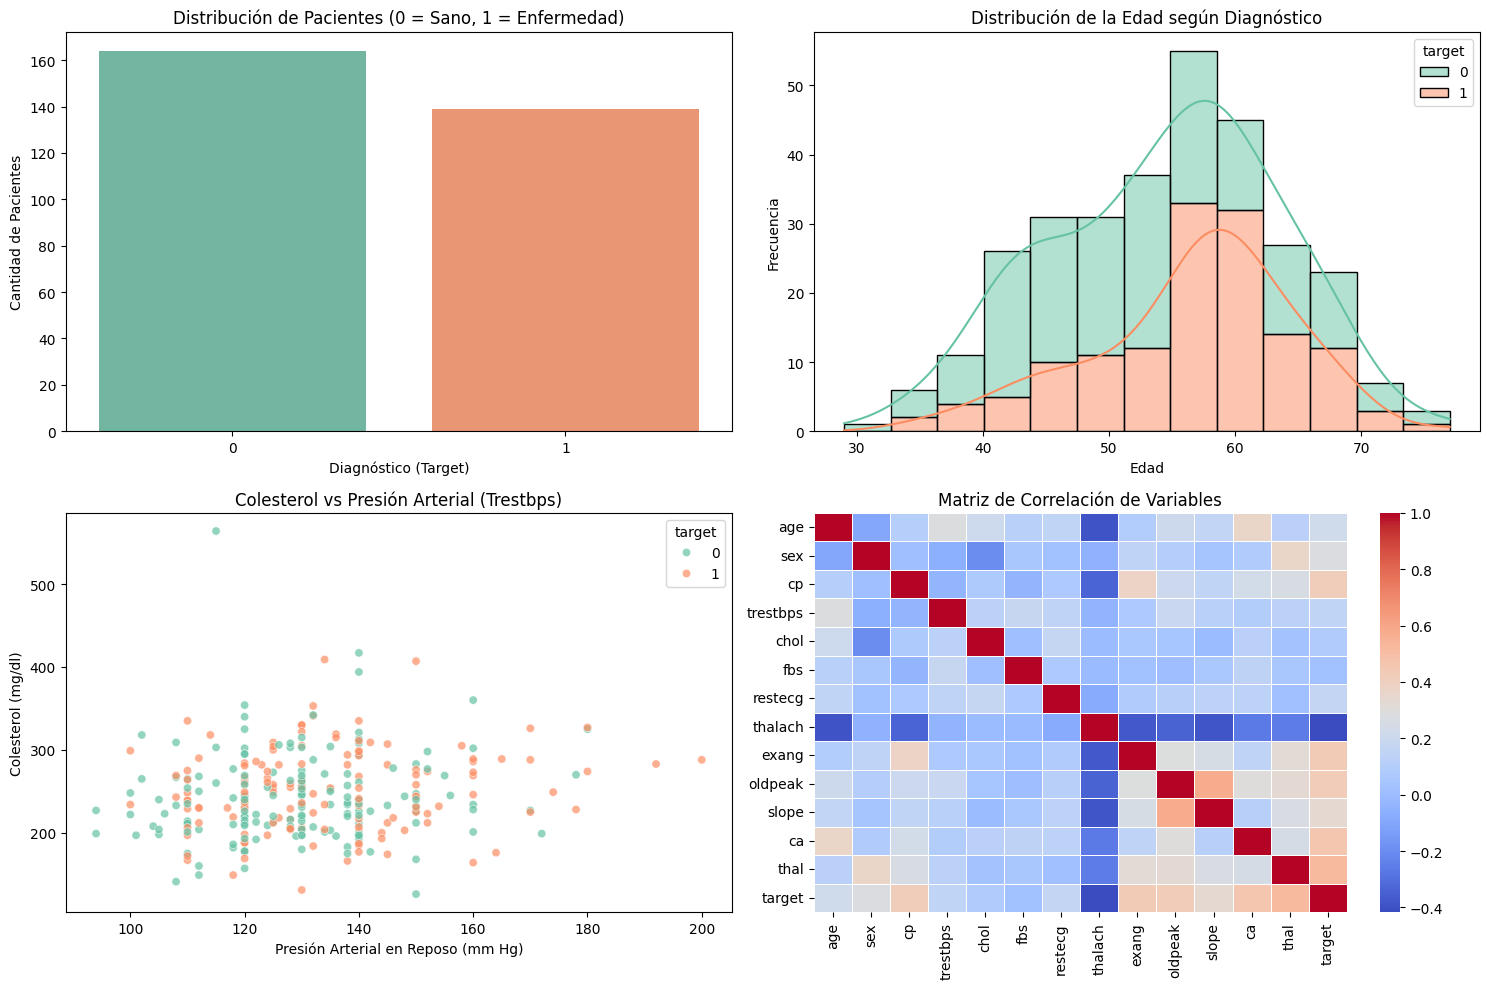

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño de la figura general
plt.figure(figsize=(15, 10))

# 1. Distribución de la Variable Objetivo (Target)
plt.subplot(2, 2, 1)
sns.countplot(
    data=df, x='target', hue='target', palette='Set2', legend=False
)
plt.title('Distribución de Pacientes (0 = Sano, 1 = Enfermedad)')
plt.xlabel('Diagnóstico (Target)')
plt.ylabel('Cantidad de Pacientes')

# 2. Distribución de la Edad según el Diagnóstico
plt.subplot(2, 2, 2)
sns.histplot(
    data=df,
    x='age',
    hue='target',
    multiple='stack',
    palette='Set2',
    kde=True,
)
plt.title('Distribución de la Edad según Diagnóstico')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')

# 3. Colesterol vs Presión Arterial en Reposo
plt.subplot(2, 2, 3)
sns.scatterplot(
    data=df, x='trestbps', y='chol', hue='target', palette='Set2', alpha=0.7
)
plt.title('Colesterol vs Presión Arterial (Trestbps)')
plt.xlabel('Presión Arterial en Reposo (mm Hg)')
plt.ylabel('Colesterol (mg/dl)')

# 4. Matriz de Correlación
plt.subplot(2, 2, 4)
correlacion = df.corr()
sns.heatmap(correlacion, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Matriz de Correlación de Variables')

plt.tight_layout()
plt.show()

**Interpretación de las visualizaciones iniciales:** la variable objetivo está casi balanceada, con 164 pacientes sin enfermedad (54 %) y 139 con enfermedad (46 %), por lo que no se requiere balanceo. Los pacientes con enfermedad tienden a tener mayor edad (mediana de 58 años frente a 52). En el diagrama de dispersión de colesterol y presión arterial no se observa una separación clara entre ambos grupos. La matriz de correlación muestra qué variables se asocian más con `target`, lo que se analiza con más detalle en la sección 3.

3. Análisis Exploratorio de Datos ampliado

En esta sección se amplía el análisis del primer avance para orientar las decisiones de modelado: valores atípicos, relación de variables categóricas con el diagnóstico y correlaciones con la variable objetivo.

valores atípicos

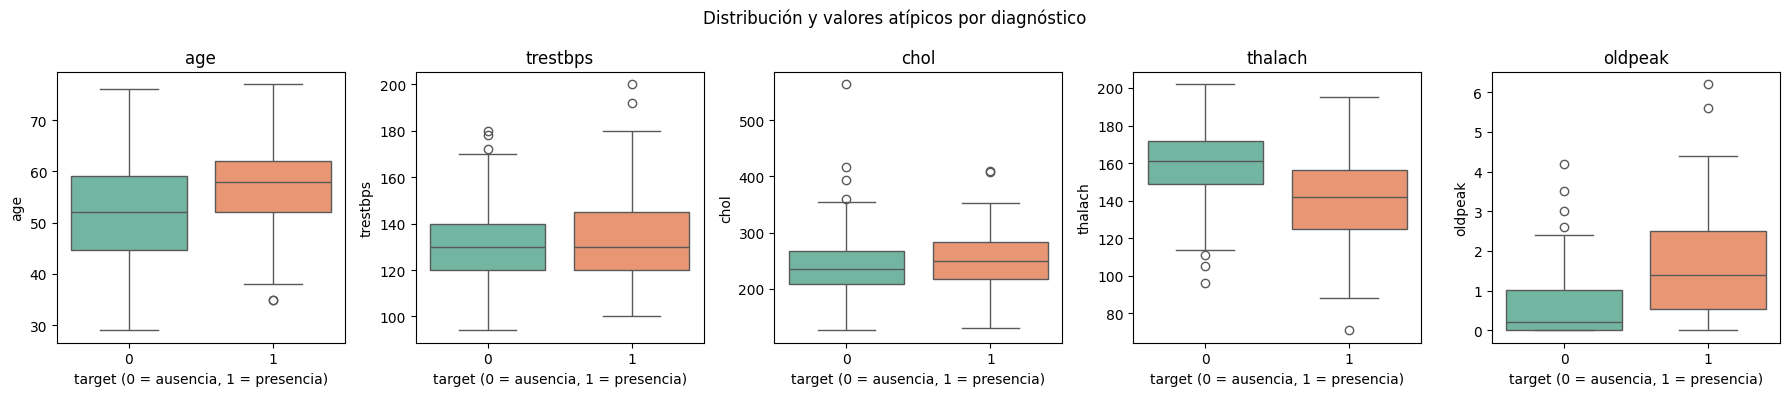

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

num_vars = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, v in zip(axes, num_vars):
    sns.boxplot(data=df, x='target', y=v, hue='target',
                palette='Set2', legend=False, ax=ax)
    ax.set_title(v)
    ax.set_xlabel('target (0 = ausencia, 1 = presencia)')
plt.suptitle('Distribución y valores atípicos por diagnóstico')
plt.tight_layout()
plt.show()

**Interpretación:** En los diagramas de caja se observan valores atípicos principalmente en `trestbps`, `chol` y `oldpeak`. Estos valores se conservan porque son clínicamente posibles y no parecen errores de captura. Además, los pacientes con enfermedad presentan una mediana de `thalach` más baja (142 frente a 161) y de `oldpeak` más alta (1.4 frente a 0.2), y una mediana de edad mayor (58 frente a 52 años) que los pacientes sin enfermedad.

**enfermedad por categoría**

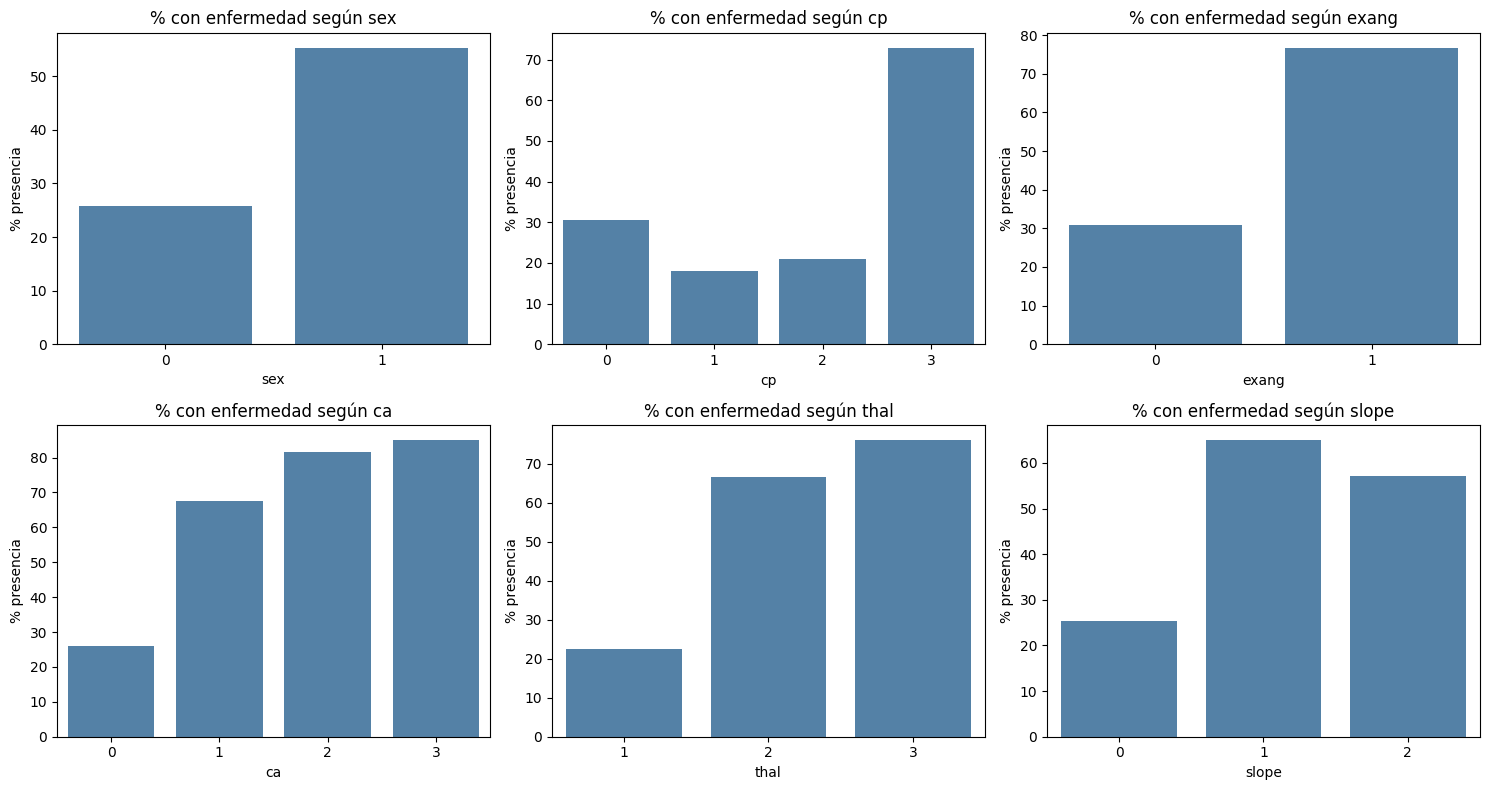

In [13]:
cats = ['sex', 'cp', 'exang', 'ca', 'thal', 'slope']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, v in zip(axes.ravel(), cats):
    tasa = df.groupby(v)['target'].mean() * 100
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax, color='steelblue')
    ax.set_title(f'% con enfermedad según {v}')
    ax.set_xlabel(v)
    ax.set_ylabel('% presencia')
plt.tight_layout()
plt.show()

**Interpretación:** El porcentaje de pacientes con presencia de enfermedad varía notablemente según las categorías de varias variables. Fue de 77 % entre quienes tuvieron angina inducida por ejercicio (`exang` = 1) y de 31 % entre quienes no. Con dolor de pecho asintomático (`cp` = 3) fue de 73 %, frente a 18 % a 30 % en los otros tipos. Aumentó con el número de vasos coloreados (`ca`): de 26 % con 0 vasos a 85 % con 3. También fue mayor en hombres (55 %) que en mujeres (26 %). Estos resultados indican asociaciones, no relaciones causales.

**correlaciones**

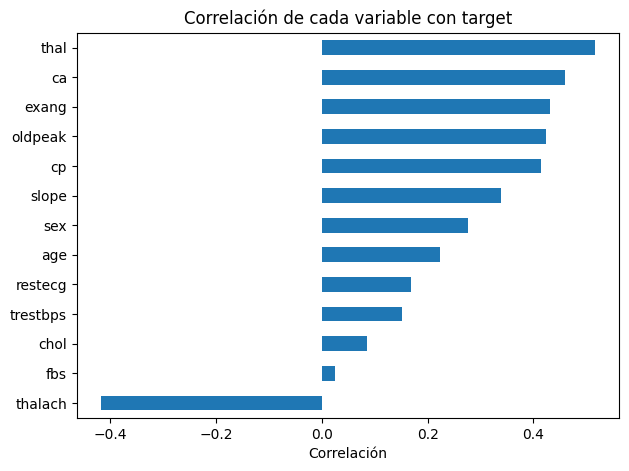

In [14]:
corr = df.corr()['target'].drop('target').sort_values()
corr.plot(kind='barh', figsize=(7, 5),
          title='Correlación de cada variable con target')
plt.xlabel('Correlación')
plt.show()

**Interpretación:** Las variables con mayor correlación positiva con el diagnóstico son `thal` (0.52), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42) y `cp` (0.41). La variable `thalach` presenta correlación negativa (-0.42): valores más bajos de frecuencia cardíaca máxima se asocian con mayor presencia de enfermedad. La correlación mide asociación lineal y no implica causalidad.

**Preparación de datos:** la versión final usada para el EDA y el entrenamiento tiene 303 registros y 14 columnas. El dataset no contiene columnas identificadoras, valores faltantes ni duplicados, por lo que no se eliminaron registros ni variables. Las variables `ca` y `thal` provienen de pruebas diagnósticas y se mantuvieron como predictoras, señalándolo como limitación. Las numéricas se escalaron con `StandardScaler` y las categóricas se codificaron con one-hot dentro del pipeline, ajustado solo con los datos de entrenamiento para evitar fuga de información.


=== Regresión logística ===
              precision    recall  f1-score   support

    Ausencia       0.93      0.82      0.87        33
   Presencia       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



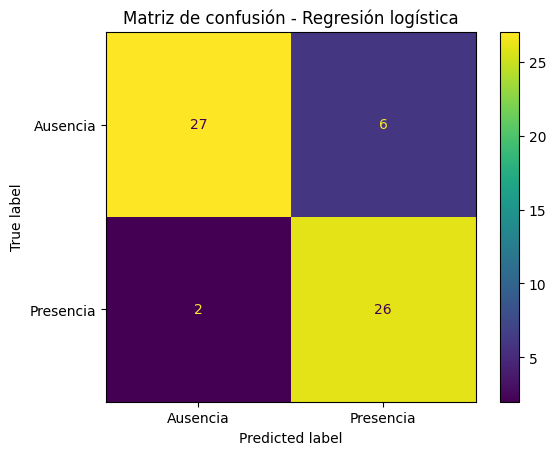

F1 en validación cruzada: [0.889 0.8   0.815 0.769 0.863]
Media: 0.827 | Desv.: 0.043

=== Árbol de decisión ===
              precision    recall  f1-score   support

    Ausencia       0.83      0.76      0.79        33
   Presencia       0.74      0.82      0.78        28

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61



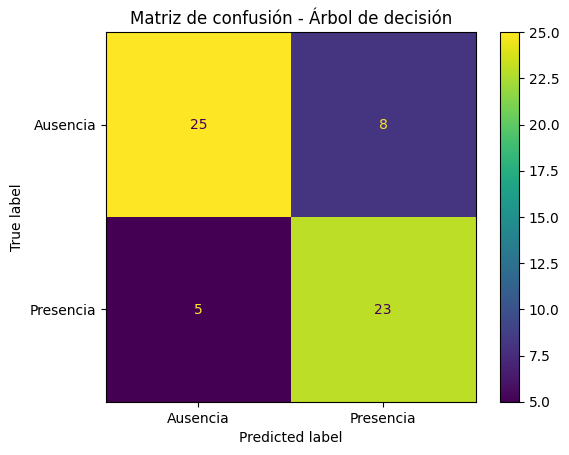

F1 en validación cruzada: [0.8   0.706 0.786 0.553 0.755]
Media: 0.72 | Desv.: 0.089


In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Separar predictoras (X) y objetivo (y)
X = df.drop(columns='target')
y = df['target']

# 2. Tipos de variables
num = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
cat = ['cp', 'restecg', 'slope', 'thal']
bin_ = ['sex', 'fbs', 'exang']

# 3. Preparación: escalar numéricas, one-hot en categóricas
prep = ColumnTransformer([
    ('num', StandardScaler(), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ('bin', 'passthrough', bin_),
])

# 4. División entrenamiento / prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 5. Modelos
modelos = {
    'Regresión logística': LogisticRegression(max_iter=1000),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=4, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 6. Entrenar y evaluar
for nombre, m in modelos.items():
    pipe = Pipeline([('prep', prep), ('modelo', m)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    print(f'\n=== {nombre} ===')
    print(classification_report(y_test, pred, target_names=['Ausencia', 'Presencia']))

    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred),
        display_labels=['Ausencia', 'Presencia']
    ).plot()
    plt.title(f'Matriz de confusión - {nombre}')
    plt.show()

    scores = cross_val_score(pipe, X, y, cv=cv, scoring='f1')
    print('F1 en validación cruzada:', scores.round(3))
    print('Media:', scores.mean().round(3), '| Desv.:', scores.std().round(3))

**Tabla comparativa de modelos**

In [8]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

filas = []
for nombre, m in modelos.items():
    pipe = Pipeline([('prep', prep), ('modelo', m)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (presencia)': precision_score(y_test, pred),
        'Recall (presencia)': recall_score(y_test, pred),
        'F1 (presencia)': f1_score(y_test, pred),
        'Falsos negativos': fn,
        'Falsos positivos': fp,
        'F1 validación cruzada (media)': cross_val_score(pipe, X, y, cv=cv, scoring='f1').mean(),
    })

comparacion = pd.DataFrame(filas).round(3)
display(comparacion)

,Modelo,Accuracy,Precision (presencia),Recall (presencia),F1 (presencia),Falsos negativos,Falsos positivos,F1 validación cruzada (media)
0,Regresión logística,0.869,0.812,0.929,0.867,2,6,0.827
1,Árbol de decisión,0.787,0.742,0.821,0.780,5,8,0.720


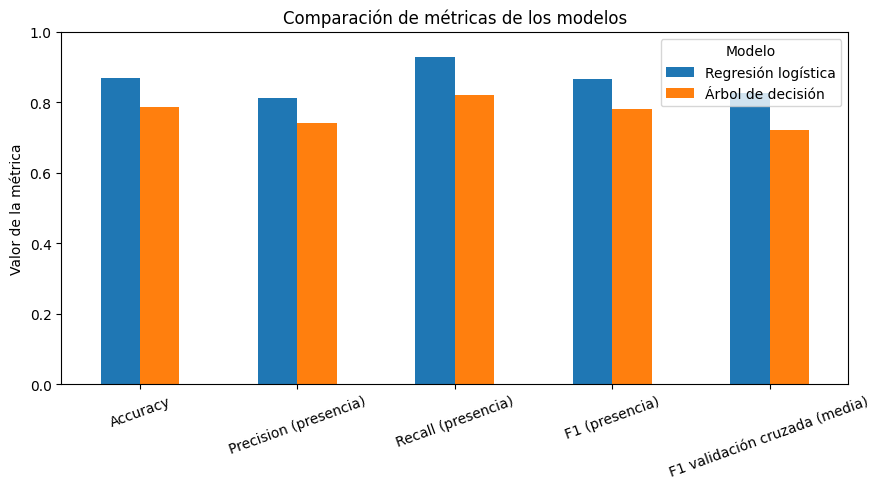

Regresión logística


,precision,recall,f1-score,support
Ausencia,0.931,0.818,0.871,33.0
Presencia,0.812,0.929,0.867,28.0


Árbol de decisión


,precision,recall,f1-score,support
Ausencia,0.833,0.758,0.794,33.0
Presencia,0.742,0.821,0.780,28.0


In [15]:
# Figura: comparación de métricas
cols = ['Accuracy', 'Precision (presencia)', 'Recall (presencia)',
        'F1 (presencia)', 'F1 validación cruzada (media)']
comparacion.set_index('Modelo')[cols].T.plot(
    kind='bar', figsize=(9, 5), ylim=(0, 1), rot=20,
    title='Comparación de métricas de los modelos')
plt.ylabel('Valor de la métrica')
plt.tight_layout()
plt.show()

# Tabla: resultados por clase
for nombre, m in modelos.items():
    pipe = Pipeline([('prep', prep), ('modelo', m)]).fit(X_train, y_train)
    rep = pd.DataFrame(classification_report(
        y_test, pipe.predict(X_test),
        target_names=['Ausencia', 'Presencia'], output_dict=True)).T.round(3)
    print(nombre)
    display(rep.loc[['Ausencia', 'Presencia']])

In [16]:
import sys, pandas, sklearn, matplotlib, seaborn
print('Python', sys.version.split()[0])
for lib in (pandas, sklearn, matplotlib, seaborn):
    print(lib.__name__, lib.__version__)

Python 3.13.18
pandas 2.2.3
sklearn 1.6.1
matplotlib 3.10.0
seaborn 0.13.2


## 4. Comparación e interpretación de los modelos

Se entrenaron dos modelos de clasificación: regresión logística y árbol de decisión (profundidad máxima 4). Los datos se dividieron en 80 % para entrenamiento (242 registros) y 20 % para prueba (61 registros) de forma estratificada, con `random_state=42`. Las variables numéricas se escalaron y las categóricas (`cp`, `restecg`, `slope`, `thal`) se codificaron con one-hot. No se realizó optimización de hiperparámetros.

| Modelo | Accuracy | Precision (presencia) | Recall (presencia) | F1 (presencia) | Falsos negativos | Falsos positivos | F1 validación cruzada |
|---|---|---|---|---|---|---|---|
| Regresión logística | 0.869 | 0.812 | 0.929 | 0.867 | 2 | 6 | 0.827 (± 0.043) |
| Árbol de decisión | 0.787 | 0.742 | 0.821 | 0.780 | 5 | 8 | 0.720 (± 0.089) |

**Resultados:** la regresión logística acertó 53 de los 61 pacientes de prueba (accuracy de 0.869). Clasificó correctamente a 26 de los 28 pacientes con enfermedad (recall de 0.929) y a 27 de los 33 sin enfermedad. El árbol de decisión acertó 48 de 61 (accuracy de 0.787), con un recall de 0.821 para la clase presencia.

**Interpretación de los errores:** en este problema el error más relevante es el falso negativo, es decir, clasificar como sano a un paciente que sí presenta la enfermedad. La regresión logística cometió 2 falsos negativos frente a 5 del árbol de decisión. También cometió menos falsos positivos (6 frente a 8). Por eso la regresión logística tuvo mejor desempeño en todas las métricas, y no solo en accuracy. Los falsos positivos son un error menos grave en un contexto de tamizaje, porque implicarían un examen adicional.

**Validación cruzada:** se aplicó validación cruzada estratificada de 5 particiones con F1 como métrica. La regresión logística obtuvo un F1 medio de 0.827 con desviación de 0.043, y el árbol de decisión de 0.720 con desviación de 0.089. La validación cruzada aporta una evidencia adicional, porque el conjunto de prueba tiene solo 61 pacientes y un resultado basado en una única división puede ser inestable. La regresión logística fue mejor y también más estable entre particiones. El árbol mostró mayor variación, lo que sugiere que su desempeño depende más de la división de los datos.

In [17]:

import json
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Pipeline final = preprocesamiento + regresión logística (entrenado SOLO con X_train,
#    igual que las métricas reportadas, para que la app y el notebook coincidan)
modelo_final = Pipeline([
    ('prep', prep),
    ('modelo', LogisticRegression(max_iter=1000)),
])
modelo_final.fit(X_train, y_train)
joblib.dump(modelo_final, 'modelo_cardiovascular.joblib')

# 2. Métricas de ambos modelos (las mismas de la tabla comparativa)
metricas = {'modelo_final': 'Regresión logística',
            'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
            'modelos': {}}
for nombre, m in modelos.items():
    pipe = Pipeline([('prep', prep), ('modelo', m)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv_scores = cross_val_score(pipe, X, y, cv=cv, scoring='f1')
    metricas['modelos'][nombre] = {
        'accuracy': float(accuracy_score(y_test, pred)),
        'precision': float(precision_score(y_test, pred)),
        'recall': float(recall_score(y_test, pred)),
        'f1': float(f1_score(y_test, pred)),
        'cv_f1_scores': [float(s) for s in cv_scores],
        'cv_f1_mean': float(cv_scores.mean()),
        'cv_f1_std': float(cv_scores.std()),
        'matriz_confusion': confusion_matrix(y_test, pred).tolist(),  # [[TN, FP], [FN, TP]]
    }
with open('metricas.json', 'w', encoding='utf-8') as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)

# 3. Conjunto de prueba (con su índice original) para verificar registros en la app
prueba = X_test.copy()
prueba['target'] = y_test
prueba.to_csv('datos_prueba.csv')

# 4. Verificación: estas probabilidades deben salir IGUALES en Streamlit
for idx in X_test.index[:3]:
    reg = X_test.loc[[idx]]
    print(f'Registro {idx}: real={y_test.loc[idx]} | '
          f'pred={modelo_final.predict(reg)[0]} | '
          f'P(presencia)={modelo_final.predict_proba(reg)[0][1]:.4f}')

Registro 219: real=0 | pred=0 | P(presencia)=0.2091
Registro 271: real=0 | pred=1 | P(presencia)=0.5868
Registro 89: real=0 | pred=0 | P(presencia)=0.0272


5. Conclusiones

**Principales hallazgos del EDA:**
- El dataset tiene 303 registros y 14 columnas, sin valores faltantes ni duplicados. La variable objetivo está casi balanceada: 164 pacientes sin enfermedad (54 %) y 139 con enfermedad (46 %).
- Se observaron valores atípicos en `trestbps`, `chol` y `oldpeak`, entre otras. Se conservaron porque son clínicamente posibles y no parecen errores de captura.
- Las variables más asociadas con la presencia de enfermedad fueron `thal` (correlación de 0.52), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42) y `cp` (0.41). La frecuencia cardíaca máxima `thalach` tuvo correlación negativa (-0.42): los pacientes con enfermedad alcanzaron una mediana de 142 frente a 161 en los pacientes sin enfermedad.
- El porcentaje de pacientes con enfermedad fue de 77 % entre quienes tuvieron angina inducida por ejercicio y de 31 % entre quienes no. Fue de 73 % entre los pacientes con dolor de pecho asintomático (`cp` = 3), y subió de 26 % con 0 vasos coloreados a 85 % con 3 vasos. También fue mayor en hombres (55 %) que en mujeres (26 %).
- Todos estos resultados corresponden a asociaciones y no permiten afirmar relaciones causales.

**Modelo con resultados más adecuados:** la regresión logística.

**Evidencias:** obtuvo el mayor accuracy (0.869 frente a 0.787), el mayor recall para la clase presencia (0.929 frente a 0.821), el menor número de falsos negativos (2 frente a 5) y un mejor F1 en validación cruzada (0.827 frente a 0.720), con menor variabilidad entre particiones. La selección se basó en estas evidencias y no solo en el accuracy.

**Errores y limitaciones:**
- El dataset es pequeño (303 registros) y el conjunto de prueba tiene solo 61 pacientes, por lo que los resultados pueden cambiar con otra división de los datos.
- No se optimizaron hiperparámetros y el árbol se limitó a profundidad 4, así que los resultados del árbol podrían mejorar con ajuste.
- La regresión logística aún comete 6 falsos positivos y 2 falsos negativos.
- Algunas variables, como `ca` y `thal`, provienen de pruebas diagnósticas adicionales, por lo que el modelo no equivale a una evaluación basada solo en datos básicos del paciente.
- Los resultados son un ejercicio académico de minería de datos y no sustituyen un diagnóstico médico.

## 6. Declaración y evaluación del uso de inteligencia artificial

### Uso 1: Primer avance
**Herramienta:** Gemini
**Propósito:** código de diagnóstico de calidad y visualizaciones iniciales, y redacción de descripciones de variables.
**Prompt completo:** "Genera el código para diagnosticar valores nulos y registros duplicados en el Cleveland Heart Disease Dataset." / "Crea las primeras visualizaciones usando Seaborn para explorar la distribución de la variable objetivo y la edad."
**Problemas identificados:** la descripción de `ca` indicaba rango 0-4 y en los datos llega hasta 3; no se definían los códigos de `cp`, `restecg` y `slope`; la conclusión decía que se eliminaron duplicados y no había ninguno.
**Ajustes realizados:** se corrigieron las descripciones y la conclusión.
**Decisión final:** se conservó el código y se corrigió el texto.

### Uso 2: Segundo avance (notebook)
**Herramienta utilizada:** Claude (Anthropic)
**Propósito:** entender el enunciado, revisar el notebook y el informe del primer avance, y obtener el código de modelado, el EDA ampliado, las gráficas adicionales y borradores de los textos de interpretación.
**Prompt completo:**                                

"Actúa como un asistente experto en ciencia de datos y aprendizaje automático. Revisa el enunciado de la guía de la práctica, la estructura actual de mi notebook, el dataset en formato CSV y el informe del primer avance (archivos adjuntos). Con base en esto:

Explica de forma detallada los pasos requeridos para completar el avance.

Genera las celdas de código en Python correspondientes al análisis exploratorio de datos (EDA) ampliado, incluyendo la codificación/mapeo de variables categóricas (restecg, slope, cp) y gráficos descriptivos.

Proporciona el código secuencial para el entrenamiento de los modelos de clasificación (Árboles de Decisión y otros evaluados) y la generación de sus matrices de confusión.

Diseña las celdas para visualizar la comparación de métricas globales, métricas por clase y versiones de las librerías utilizadas.

Redacta los borradores del análisis interpretativo para los incisos de resultados y discusión, indicando de manera exacta en qué orden y sección del notebook debe colocarse cada celda de código y texto."                                     **Problemas identificados:** (1) los significados de `restecg`, `slope` y `cp` se dedujeron al principio y no venían de la documentación del archivo; después se contrastaron con la documentación de UCI y la descripción de la versión de Kaggle. (2) La primera estimación de falsos negativos del árbol se hizo con una captura parcial; luego se confirmó al ejecutar el código completo (5). (3) En varias respuestas se entregaron más pasos de los pedidos y hubo que repetir dónde pegar cada celda. (4) Los textos de interpretación venían con cifras que hubo que contrastar con las salidas del notebook. (5) Al revisar el notebook se detectó que faltaba la celda que entrena los modelos, de la que dependían las demás.
**Ajustes realizados:** se pegaron y ejecutaron las celdas en orden; se completaron el encabezado, el enlace y los nombres; se compararon las cifras de los textos con las salidas; se añadieron las celdas de gráfica de métricas, métricas por clase y versiones de librerías; y se ejecutó todo con "Restart & Run All".
**Decisión final:** se conservó el código de modelado y de EDA porque se ejecutó sin errores y sus resultados coinciden con las salidas del notebook. Las interpretaciones se mantuvieron porque coinciden con los números obtenidos.                                       ###Uso 3: Segundo informe (redacción)
Herramienta utilizada: Claude (Anthropic)

Propósito: Redacción y consolidación del informe académico del segundo corte, estructuración metodológica, sistematización de resultados a partir de las salidas del notebook, ampliación de la revisión bibliográfica y aplicación de formato APA 7.

Prompt completo:

"Con base en el notebook final ejecutado, la guía de la práctica y el informe previo (adjuntos), redacta la segunda entrega del informe académico. El documento debe:

Consolidar las secciones de Metodología y Resultados Preliminares asegurando coherencia con los valores métricos obtenidos en el notebook.

Mantener un estilo de redacción académico formal en español.

Ampliar el marco de referencias bibliográficas relacionadas con el conjunto de datos de enfermedades cardíacas de la UCI y aplicar estrictamente la normativa de citación y referencias APA en su 7.ª edición.

Incorporar la estructura completa especificada en la captura de requerimientos adjunta."
